# Delta hedging: concept, maths and a working simulator

This notebook builds a delta hedging simulator from first principles and uses it to check, with numbers, every claim it makes along the way. It follows the structure of the reference document *Delta Hedging, From First Principles to a Working Simulator*; section numbers such as "PDF 2.6" point to it.

**The set-up used throughout.** A desk **sells** one European call option and delta-hedges it until expiry.

| Symbol | Meaning | Default |
|---|---|---|
| $S_0$ | stock price today | 100 |
| $K$ | strike | 100 (at the money) |
| $T$ | time to expiry | 0.25 years (63 trading days) |
| $r$ | risk-free rate, continuous | 4% |
| $\sigma_i$ | **implied** vol: the vol the option is sold at | 20% |
| $\sigma_r$ | **realised** vol: how much the stock actually moves | 20% unless stated |
| $N$ | number of hedge trades (initial hedge plus $N-1$ rebalances) | 63 (daily) |

**The answer in four lines.**

1. Delta hedging means holding $\Delta = \partial V / \partial S$ shares against an option you sold, so that small moves in the stock no longer change your P&L.
2. In the Black-Scholes world this replicates the option's payoff: the premium you received pays for the hedge. So the hedged P&L has a mean of about zero.
3. What remains is a bet on volatility. If the stock moves more than the vol you charged for, the seller loses; if less, the seller wins.
4. Hedging only $N$ times adds noise with standard deviation about $\sqrt{\pi/4}\;\nu\,\sigma/\sqrt{N}$ (here about 0.44, a tenth of the premium), and trading costs make "more often" a trade-off, not a free improvement.

All simulated data here is synthetic. Section 10 repeats the exercise on S&P 500 history.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "delta_hedging").is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Code, display

import delta_hedging as dh
from delta_hedging import experiments as ex
from delta_hedging import plots

plots.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)

S0, K, T, r, sigma = 100.0, 100.0, 0.25, 0.04, 0.20


def show_source(obj):
    "Print the package's own source for a function, so there is one copy of the code."
    display(Code(inspect.getsource(obj), language="python"))

---
# Part 1: The concept

## 1.1 What delta is

A call option gives its owner the right to buy the stock at the strike $K$ on the expiry date. Its payoff is $\max(S_T - K, 0)$. Before expiry it has a value $V$ that depends on the stock price $S$, the time left, the volatility and the interest rate.

**Delta** is the slope of that value with respect to the stock price:

$$\Delta = \frac{\partial V}{\partial S}$$

If the stock rises by 1, the option gains about $\Delta$. For our at-the-money call $\Delta \approx 0.56$.

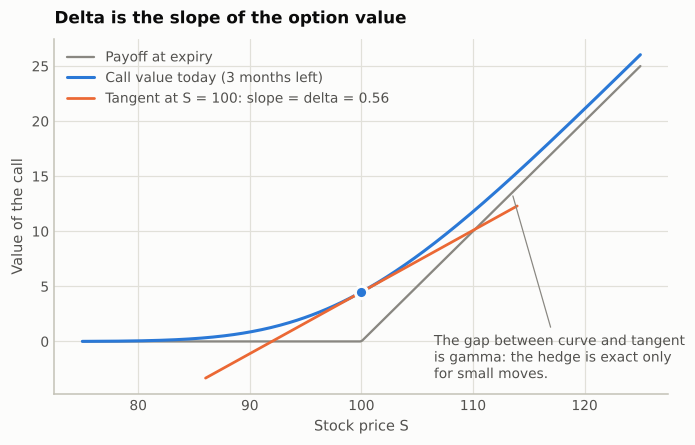

Call value at S = 100:  4.4852      delta: 0.5596
stock + 0.1: option changes by  0.0562, delta predicts  0.0560, gap 0.0002
stock + 1.0: option changes by  0.5792, delta predicts  0.5596, gap 0.0195
stock +10.0: option changes by  7.2942, delta predicts  5.5962, gap 1.6980


In [2]:
fig = plots.fig_delta_tangent(S0, K, T, r, sigma)
plt.show()

c0 = dh.bs_price(S0, K, T, r, sigma)
d0 = dh.bs_delta(S0, K, T, r, sigma)
print(f"Call value at S = 100:  {c0:.4f}      delta: {d0:.4f}")
for bump in (0.1, 1.0, 10.0):
    actual = dh.bs_price(S0 + bump, K, T, r, sigma) - c0
    print(f"stock +{bump:>4}: option changes by {actual:7.4f}, delta predicts {d0 * bump:7.4f}, "
          f"gap {actual - d0 * bump:6.4f}")

The prediction is nearly exact for a small move and visibly off for a large one. The gap is **gamma**, the curvature of the blue line. Keep it in mind: it is the reason a delta hedge needs rebalancing and the source of everything interesting later.

## 1.2 Why a desk hedges, and what "replication" means

A desk that sells options to clients earns its living from the margin it charges, not from guessing where the stock goes. If it sells a call and does nothing, it is exposed to an unlimited loss if the stock rallies. So it buys $\Delta$ shares. Now, to first order:

$$\underbrace{-\Delta \cdot dS}_{\text{short option loses}} \;+\; \underbrace{\Delta \cdot dS}_{\text{shares gain}} \;=\; 0$$

As $S$ and time change, $\Delta$ changes, so the hedge must be **rebalanced**. That is the "dynamic" in dynamic hedging.

Two words carry the theory:

* **Self-financing.** After the premium comes in, no money is added or taken out. Shares are bought with borrowed cash; shares sold repay it; the cash balance earns or pays the risk-free rate.
* **Replication.** Black and Scholes showed that such a strategy, started with exactly the option's fair price, ends up worth exactly the option's payoff (if you could rebalance continuously). The seller's stock-plus-cash portfolio pays off what the seller owes.

Whatever the portfolio is worth at expiry, minus the payoff owed, is the **hedging error**. That one number per path is what the simulator measures.

## 1.3 What the hedge removes and what it leaves

| Risk | Removed by delta hedging? | Comment |
|---|---|---|
| Direction (first order in $dS$) | Yes, locally | The definition of delta-neutral |
| Gamma (second order in $dS$) | No | Short gamma loses on large moves in either direction |
| Theta (time decay) | No | For the seller it is income, the "rent" that pays for gamma |
| Vega (change in implied vol) | No | Re-marks the position even if the stock is still |
| Jumps and gaps | No | You cannot rebalance through a gap |
| Model risk | No | Wrong vol, smile, stochastic vol |
| Costs | Made worse | Every rebalance pays the spread |

## 1.4 The core intuition

With direction gone, a delta-hedged **short** option does two things each day:

* it **earns theta**: the option it is short loses time value;
* it **loses gamma**: $\tfrac12\Gamma\,(\Delta S)^2$, whichever way the stock moved, because the hedge was one step behind.

Black-Scholes sets the price so that the two cancel **exactly when the stock moves with the implied volatility**. More movement than implied: gamma losses beat theta income and the seller loses. Less: the seller wins. That is why traders talk about "selling vol" and "buying vol". Part 6 shows this in the simulator.

---
# Part 2: The maths, step by step

## 2.1 A model for the stock: geometric Brownian motion

$$dS_t = \mu S_t\,dt + \sigma S_t\,dW_t$$

$W$ is a Brownian motion: over a short time $dt$ its increment $dW$ is normal with mean 0 and variance $dt$. $\mu$ is the expected return and $\sigma$ the volatility. Both terms are proportional to $S$, so returns, not price changes, have a fixed distribution and the price stays positive.

## 2.2 Itô's lemma and the exact step

Ordinary calculus says $df = f'(S)\,dS$. With Brownian motion that misses a term, because $(dW)^2 = dt$ is not negligible. For a smooth function $f(t, S)$, **Itô's lemma** is

$$df = \Big(\frac{\partial f}{\partial t} + \mu S \frac{\partial f}{\partial S} + \tfrac12 \sigma^2 S^2 \frac{\partial^2 f}{\partial S^2}\Big)dt + \sigma S \frac{\partial f}{\partial S}\,dW$$

Apply it to $f = \ln S$, where $\partial f/\partial S = 1/S$ and $\partial^2 f/\partial S^2 = -1/S^2$:

$$d\ln S = \big(\mu - \tfrac12\sigma^2\big)\,dt + \sigma\,dW$$

The right-hand side no longer contains $S$, so it integrates exactly over a step of any size $\Delta t$:

$$\boxed{S_{t+\Delta t} = S_t \exp\!\Big[\big(\mu - \tfrac12\sigma^2\big)\Delta t + \sigma\sqrt{\Delta t}\;Z\Big]}, \qquad Z \sim N(0,1)$$

This is what the simulator uses. It is the exact solution, so the simulated prices have the right distribution on the time grid with no discretisation error. The $-\tfrac12\sigma^2$ is the "volatility drag" that people often forget.

In [3]:
show_source(dh.simulate_gbm)

def simulate_gbm(S0, mu, sigma, T, n_steps, n_paths, rng):
    """Simulate GBM paths on an even time grid.

    Parameters
    ----------
    S0 : float        starting price
    mu : float        real-world drift of the price (per year)
    sigma : float     realised volatility of the world (per year)
    T : float         horizon in years
    n_steps : int     number of time steps; the grid has n_steps + 1 points
    n_paths : int     number of independent paths
    rng : numpy.random.Generator, e.g. ``np.random.default_rng(42)``

    Returns
    -------
    S : ndarray, shape (n_paths, n_steps + 1), with S[:, 0] == S0.
    """
    dt = T / n_steps
    Z = rng.standard_normal((n_paths, n_steps))
    log_inc = (mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z  # Ito drift correction
    S = np.empty((n_paths, n_steps + 1))
    S[:, 0] = S0
    S[:, 1:] = S0 * np.exp(np.cumsum(log_inc, axis=1))
    return S

Line by line: `Z` holds one standard normal per path and step; `log_inc` is the boxed formula's exponent; `cumsum` adds the log increments along each path; `exp` turns log prices back into prices.

Two checks that the paths are right. The mean of $S_T$ must be $S_0 e^{\mu T}$, and the standard deviation of $\ln(S_T/S_0)$ must be $\sigma\sqrt{T}$.

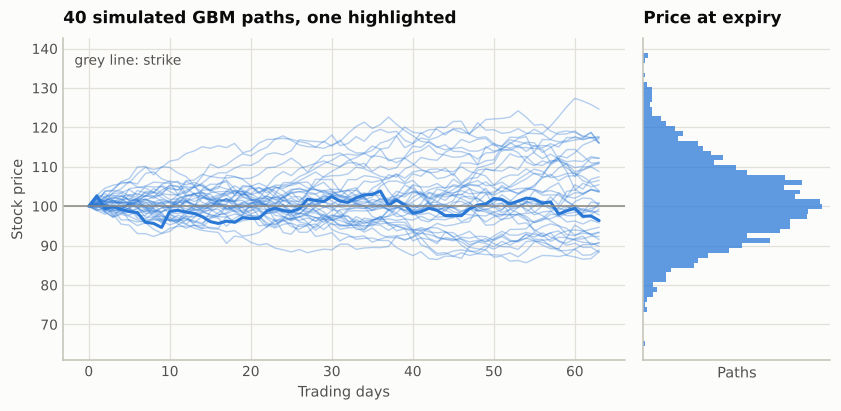

E[S_T]            simulated 102.0294 (+/- 0.0323)   theory 102.0201
std of log return simulated 0.10000             theory 0.10000
mean log return   simulated 0.01509             theory 0.01500   <- mu minus the volatility drag


In [4]:
rng = np.random.default_rng(3)
paths = dh.simulate_gbm(S0, mu=r, sigma=sigma, T=T, n_steps=63, n_paths=2000, rng=rng)
fig = plots.fig_sample_paths(paths, T, K=K)
plt.show()

mu_test = 0.08
big = dh.simulate_gbm(S0, mu_test, sigma, T, 4, 400_000, np.random.default_rng(0))[:, -1]
se = big.std() / np.sqrt(big.size)
print(f"E[S_T]            simulated {big.mean():.4f} (+/- {2 * se:.4f})   theory {S0 * np.exp(mu_test * T):.4f}")
print(f"std of log return simulated {np.log(big / S0).std():.5f}             theory {sigma * np.sqrt(T):.5f}")
print(f"mean log return   simulated {np.log(big / S0).mean():.5f}             theory {(mu_test - 0.5 * sigma**2) * T:.5f}"
      "   <- mu minus the volatility drag")

## 2.3 The Black-Scholes hedging argument

Hold one option and short $\Delta$ shares: $\Pi = V - \Delta S$. Applying Itô's lemma to $V(t, S)$:

$$d\Pi = \Big(\frac{\partial V}{\partial t} + \mu S \frac{\partial V}{\partial S} + \tfrac12\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}\Big)dt + \sigma S\frac{\partial V}{\partial S}\,dW \;-\; \Delta\,(\mu S\,dt + \sigma S\,dW)$$

Now choose $\Delta = \partial V/\partial S$. The $dW$ terms cancel, and so do the $\mu$ terms:

$$d\Pi = \Big(\frac{\partial V}{\partial t} + \tfrac12\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2}\Big)dt$$

There is no randomness left, so the portfolio is riskless over the next instant. A riskless portfolio must earn the risk-free rate or there would be an arbitrage: $d\Pi = r\Pi\,dt = r(V - S\,\partial V/\partial S)\,dt$. Setting the two expressions equal gives the **Black-Scholes PDE**:

$$\frac{\partial V}{\partial t} + \tfrac12\sigma^2 S^2 \frac{\partial^2 V}{\partial S^2} + rS\frac{\partial V}{\partial S} - rV = 0, \qquad V(T, S) = \max(S - K, 0)$$

**$\mu$ has disappeared.** The option's price does not depend on the stock's expected return, only on its volatility. Section 6.3 tests this directly.

## 2.4 The formulas

With $\tau = T - t$ the time left:

$$d_1 = \frac{\ln(S/K) + (r + \tfrac12\sigma^2)\tau}{\sigma\sqrt\tau}, \qquad d_2 = d_1 - \sigma\sqrt\tau$$

$$C = S\,N(d_1) - K e^{-r\tau} N(d_2), \qquad P = K e^{-r\tau} N(-d_2) - S\,N(-d_1)$$

$N$ is the standard normal distribution function and $\varphi$ its density. Calls and puts are tied together by **put-call parity**: $C - P = S - Ke^{-r\tau}$.

## 2.5 The Greeks

| Greek | Definition | Call | Put |
|---|---|---|---|
| Delta $\Delta$ | $\partial V/\partial S$ | $N(d_1)$ | $N(d_1) - 1$ |
| Gamma $\Gamma$ | $\partial^2 V/\partial S^2$ | $\varphi(d_1)/(S\sigma\sqrt\tau)$ | same |
| Vega $\nu$ | $\partial V/\partial\sigma$ | $S\varphi(d_1)\sqrt\tau$ | same |
| Theta $\Theta$ | $\partial V/\partial t$ | $-\dfrac{S\varphi(d_1)\sigma}{2\sqrt\tau} - rKe^{-r\tau}N(d_2)$ | $-\dfrac{S\varphi(d_1)\sigma}{2\sqrt\tau} + rKe^{-r\tau}N(-d_2)$ |

A useful identity links two of them: $\nu = \sigma\,\tau\,S^2\,\Gamma$. Vega is gamma seen over the option's whole life.

The code is a direct transcription. `norm.cdf` is $N$ and `norm.pdf` is $\varphi$. The optional `q` is a dividend yield, zero until the real-data section.

In [5]:
show_source(dh.bs_d1_d2)
show_source(dh.bs_price)
show_source(dh.bs_greeks)

def bs_d1_d2(S, K, tau, r, sigma, q=0.0):
    """Return (d1, d2). Requires tau > 0 and sigma > 0."""
    sqrt_tau = np.sqrt(tau)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * tau) / (sigma * sqrt_tau)
    return d1, d1 - sigma * sqrt_tau

def bs_price(S, K, tau, r, sigma, kind="call", q=0.0):
    """Black-Scholes value of a European call or put."""
    _check_kind(kind)
    d1, d2 = bs_d1_d2(S, K, tau, r, sigma, q)
    df_r = np.exp(-r * tau)  # discount factor on the strike
    df_q = np.exp(-q * tau)  # dividend discount on the stock
    if kind == "call":
        return S * df_q * norm.cdf(d1) - K * df_r * norm.cdf(d2)
    return K * df_r * norm.cdf(-d2) - S * df_q * norm.cdf(-d1)

def bs_greeks(S, K, tau, r, sigma, kind="call", q=0.0):
    """Return a dict with delta, gamma, vega and theta.

    Units: vega is per 1.00 of volatility (divide by 100 for "per vol
    point"); theta is per year (divide by 252 for "per trading day").
    Gamma and vega are the same for a call and a put.
    """
    _check_kind(kind)
    d1, d2 = bs_d1_d2(S, K, tau, r, sigma, q)
    pdf = norm.pdf(d1)
    df_r = np.exp(-r * tau)
    df_q = np.exp(-q * tau)
    sqrt_tau = np.sqrt(tau)

    gamma = df_q * pdf / (S * sigma * sqrt_tau)
    vega = S * df_q * pdf * sqrt_tau
    decay = -S * df_q * pdf * sigma / (2.0 * sqrt_tau)  # the part of theta shared by both
    if kind == "call":
        delta = df_q * norm.cdf(d1)
        theta = decay - r * K * df_r * norm.cdf(d2) + q * S * df_q * norm.cdf(d1)
    else:
        delta = df_q * (norm.cdf(d1) - 1.0)
        theta = decay + r * K * df_r * norm.cdf(-d2) - q * S * df_q * norm.cdf(-d1)
    return {"delta": delta, "gamma": gamma, "vega": vega, "theta": theta}

**Check against the reference values** (PDF 2.4 and 2.5), then run the three sanity checks the PDF asks for before trusting any chart: put-call parity, Greeks against finite differences, and the PDE itself.

In [6]:
g = dh.bs_greeks(S0, K, T, r, sigma)
C, P = dh.bs_price(S0, K, T, r, sigma, "call"), dh.bs_price(S0, K, T, r, sigma, "put")
d1, d2 = dh.bs_d1_d2(S0, K, T, r, sigma)
print(f"d1 = {d1:.4f}, d2 = {d2:.4f}")
display(pd.DataFrame({
    "this notebook": [C, P, g["delta"], g["gamma"], g["vega"], g["vega"] / 100, g["theta"], g["theta"] / 252],
    "PDF says": [4.49, 3.49, 0.560, 0.0394, 19.72, 0.197, -9.95, -0.039],
}, index=["call", "put", "delta", "gamma", "vega per 1.00 vol", "vega per vol point",
          "theta per year", "theta per trading day"]))

# 1. Put-call parity
assert abs((C - P) - (S0 - K * np.exp(-r * T))) < 1e-10

# 2. Greeks against finite differences
h = 1e-4 * S0
up, dn = dh.bs_price(S0 + h, K, T, r, sigma), dh.bs_price(S0 - h, K, T, r, sigma)
fd_delta, fd_gamma = (up - dn) / (2 * h), (up - 2 * C + dn) / h**2
assert abs(fd_delta - g["delta"]) < 1e-6 and abs(fd_gamma - g["gamma"]) < 1e-4

# 3. The PDE: theta + 1/2 sigma^2 S^2 gamma + r S delta - r V = 0
pde = g["theta"] + 0.5 * sigma**2 * S0**2 * g["gamma"] + r * S0 * g["delta"] - r * C
assert abs(pde) < 1e-8

# 4. vega = sigma * tau * S^2 * gamma
assert abs(g["vega"] - sigma * T * S0**2 * g["gamma"]) < 1e-10
print(f"parity, finite-difference Greeks, PDE residual ({pde:.1e}) and the vega-gamma identity all pass")

d1 = 0.1500, d2 = 0.0500


,this notebook,PDF says
call,4.4852,4.4900
put,3.4902,3.4900
delta,0.5596,0.5600
gamma,0.0394,0.0394
vega per 1.00 vol,19.7240,19.7200
vega per vol point,0.1972,0.1970
theta per year,-9.9486,-9.9500
theta per trading day,-0.0395,-0.0390


parity, finite-difference Greeks, PDE residual (4.7e-16) and the vega-gamma identity all pass


## 2.6 Theta against gamma, and the P&L of a hedged position

Write the PDE in terms of the Greeks: $\Theta + \tfrac12\sigma^2S^2\Gamma + rS\Delta - rV = 0$, or

$$\Theta - r(V - S\Delta) = -\tfrac12\sigma^2 S^2\Gamma$$

In words: **the time decay you pay, net of financing, exactly offsets the gamma gains you expect at volatility $\sigma$.**

Now price and hedge at the implied vol $\sigma_i$ while the stock really moves with $\sigma_r$. Over a short step $\delta t$ the hedged **seller** makes

$$\delta\text{P\&L} \approx \tfrac12\,\Gamma_i S^2\Big[\sigma_i^2\,\delta t - \Big(\frac{\delta S}{S}\Big)^2\Big]$$

which has expectation $\tfrac12\Gamma_i S^2(\sigma_i^2 - \sigma_r^2)\,\delta t$. Read it as *dollar gamma × (implied variance − realised variance) × time*. Summed to expiry with interest (El Karoui, Jeanblanc-Picqué and Shreve, 1998):

$$\text{P\&L}_T = \tfrac12\int_0^T e^{r(T-t)}\,\Gamma_i(t, S_t)\,S_t^2\,\big(\sigma_i^2 - \sigma_r^2(t)\big)\,dt$$

Two consequences:

* **The sign is known** if realised vol is always below (or always above) implied.
* **The size depends on the path**, because the variance gap is weighted by dollar gamma $\Gamma S^2$, which is largest near the strike close to expiry.

A back-of-envelope version: P&L $\approx \nu \times (\sigma_i - \sigma_r)$. With vega 19.7, realised 25% against implied 20% costs the seller about $19.7 \times 0.05 \approx 1.0$, more than a fifth of the 4.49 premium.

---
# Part 3: The hedging loop in code

Here is the whole strategy in about twenty lines, exactly as in PDF 3.3. This is the function to understand; everything else is built on it.

**Timing convention.** With `n_steps` intervals there are $N$ hedge trades, at $t_0, \dots, t_{N-1}$. The position is unwound at $T$. So $N = 63$ over three months is daily hedging.

In [7]:
def hedge_short_call_minimal(S, K, T, r, sigma_imp, cost=0.0):
    "Short 1 call, delta-hedge at implied vol. Returns the terminal P&L of each path."
    n_steps = S.shape[1] - 1
    dt = T / n_steps
    growth = np.exp(r * dt)

    premium = dh.bs_price(S[:, 0], K, T, r, sigma_imp)          # (1) cash received at t0
    delta = dh.bs_delta(S[:, 0], K, T, r, sigma_imp)            # (2) shares bought at t0
    cash = premium - delta * S[:, 0] - cost * np.abs(delta) * S[:, 0]

    for i in range(1, n_steps):                                 # rebalance at t1 .. t_{N-1}
        cash *= growth                                          # (3) interest over (t_{i-1}, t_i]
        tau = T - i * dt                                        #     time left, strictly > 0
        new_delta = dh.bs_delta(S[:, i], K, tau, r, sigma_imp)  # (4) uses S at t_i only
        trade = new_delta - delta
        cash -= trade * S[:, i] + cost * np.abs(trade) * S[:, i]   # (5) self-financing, (6) cost
        delta = new_delta

    cash *= growth                                              # last interval (t_{N-1}, T]
    S_T = S[:, -1]
    cash += delta * S_T - cost * np.abs(delta) * S_T            # sell the hedge
    return cash - np.maximum(S_T - K, 0.0)                      # (7) minus the payoff owed

| Line | Code | Concept |
|---|---|---|
| (1) | `premium = bs_price(...)` | The seller receives the Black-Scholes price. This is the only money that ever comes in. |
| (2) | `delta = bs_delta(...)`, `cash = premium - delta * S` | The premium funds the first hedge. Cash is usually negative: the desk borrows to buy shares. |
| (3) | `cash *= growth` | The risk-free account. $e^{r\,\delta t}$ per step, paid on borrowings as well as earned on deposits. |
| (4) | `new_delta = bs_delta(S[:, i], ...)` | The new hedge ratio uses only what is known at $t_i$. Using `S[:, i + 1]` here is the classic look-ahead bug. |
| (5) | `cash -= trade * S` | **Self-financing**: shares bought are paid for from cash, shares sold add to it. Nothing comes from outside. |
| (6) | `cost * abs(trade) * S` | Proportional cost on the value traded. |
| (7) | `cash + delta * S_T - payoff` | **Hedging error**: what the replicating portfolio is worth, minus what the seller owes. |

The package's `hedge_short_option` is this same loop with extra options (puts, a separate hedging vol, no-trade bands, dividends, a per-step history). The next cell checks that the two agree to rounding error.

In [8]:
S = dh.simulate_gbm(S0, r, sigma, T, 63, 5000, np.random.default_rng(42))
mine = hedge_short_call_minimal(S, K, T, r, sigma, cost=0.001)
package = dh.hedge_short_option(S, K, T, r, sigma, cost=0.001).pnl
print("largest difference between the 20-line version and the package:", np.abs(mine - package).max())
assert np.allclose(mine, package, atol=1e-10)

largest difference between the 20-line version and the package: 1.8474111129762605e-13


## 3.1 One path, by hand

Take a single simulated path and watch the ledger. `hedging_error` is the running value of (cash + shares − option): what the seller would have made if the book were closed at fair value at that moment.

,t,S,delta,trade,stock_value,cash,option_value,hedging_error
step,,,,,,,,
0,0.0000,100.0000,0.5596,0.5596,55.9618,-51.4765,4.4852,0.0000
1,0.0040,102.6128,0.6587,0.0990,67.5867,-61.6474,6.0387,-0.0995
2,0.0079,99.3694,0.5332,-0.1255,52.9833,-49.1902,4.0615,-0.2683
3,0.0119,99.9021,0.5542,0.0210,55.3684,-51.2990,4.3112,-0.2418
61,0.2421,97.4415,0.0767,-0.3392,7.4699,-7.9027,0.0594,-0.4922
62,0.2460,97.5246,0.0244,-0.0523,2.3781,-2.8058,0.0112,-0.4389
63,0.2500,96.3548,0.0244,-0.0244,2.3496,-2.8062,0.0000,-0.4567


Step 0, by hand:
  premium received               4.4852
  buy 0.5596 shares at 100     -55.9618
  cash after the trade         -51.4765   (ledger: -51.4765)
Step 1, by hand:
  interest on cash, one day     -0.0082
  stock moved to 102.6128; new delta 0.6587; trade +0.0990 shares
  cash after the trade         -61.6474   (ledger: -61.6474)


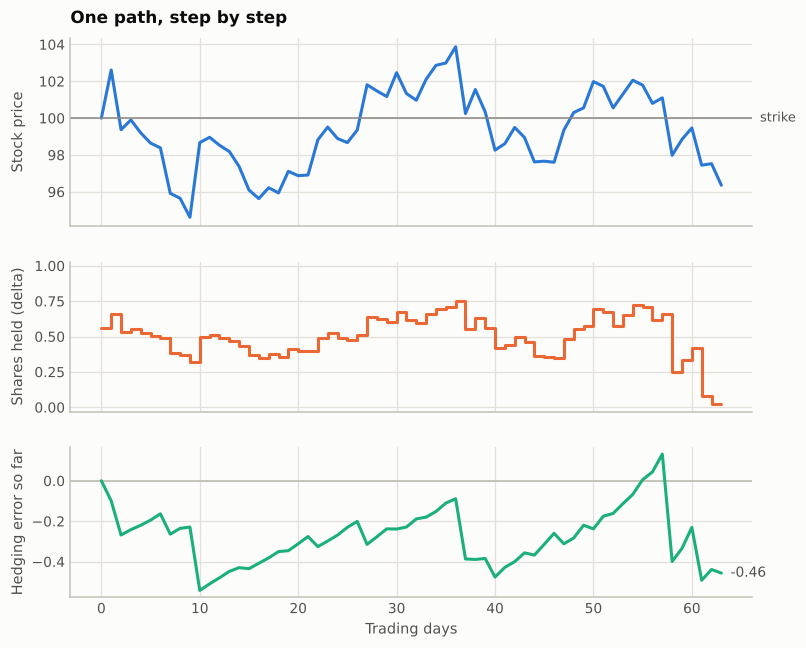

In [9]:
ledger = dh.hedge_ledger(paths[0], K, T, r, sigma)
display(pd.concat([ledger.head(4), ledger.tail(3)]))

row0, row1 = ledger.iloc[0], ledger.iloc[1]
dt = T / 63
print("Step 0, by hand:")
print(f"  premium received            {c0:9.4f}")
print(f"  buy {row0.delta:.4f} shares at 100    {-row0.delta * 100:9.4f}")
print(f"  cash after the trade        {c0 - row0.delta * 100:9.4f}   (ledger: {row0.cash:.4f})")
print("Step 1, by hand:")
interest = row0.cash * (np.exp(r * dt) - 1)
print(f"  interest on cash, one day   {interest:9.4f}")
print(f"  stock moved to {row1.S:.4f}; new delta {row1.delta:.4f}; trade {row1.trade:+.4f} shares")
print(f"  cash after the trade        {row0.cash + interest - row1.trade * row1.S:9.4f}   (ledger: {row1.cash:.4f})")

fig = plots.fig_single_path(ledger, K)
plt.show()

How to read the three panels together:

* The hedge ratio follows the stock: the desk **buys as the stock rises and sells as it falls**. That is buying high and selling low, and it is the mechanical form of being short gamma.
* On quiet days the hedging error drifts **up**: that is theta being collected.
* On days with a large move in either direction it drops: that is the gamma loss.

On this path the seller ends 0.46 behind. That is one draw from a distribution, which is the subject of the next part.

---
# Part 4: Monte Carlo. What the hedge achieves

One path proves nothing, so simulate 20,000 and look at the distribution of the terminal P&L. First, hedged against unhedged.

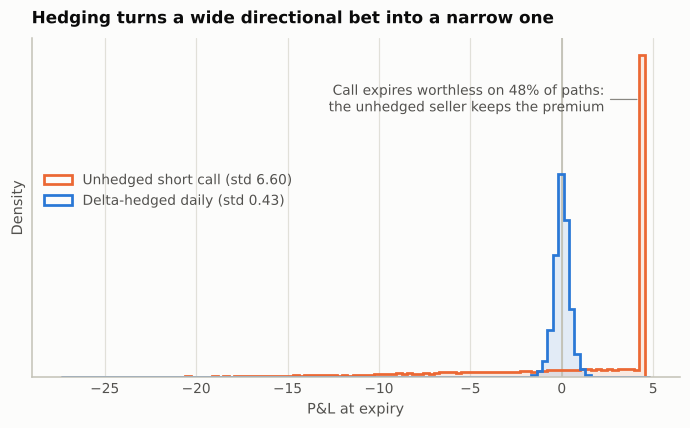

premium received: 4.485
unhedged: std 6.60, worst path -45.6
hedged:   std 0.43, worst path -2.5


In [10]:
freq, pnl = ex.frequency_study(n_values=(21, 63, 252), n_paths=20_000, seed=42)
fig = plots.fig_hedged_vs_unhedged(pnl)
plt.show()
print(f"premium received: {freq.attrs['premium']:.3f}")
print(f"unhedged: std {pnl['unhedged'].std():.2f}, worst path {pnl['unhedged'].min():.1f}")
print(f"hedged:   std {pnl[63].std():.2f}, worst path {pnl[63].min():.1f}")

The unhedged seller keeps the whole premium about half the time and otherwise loses, sometimes several times the premium. Daily hedging cuts the standard deviation by a factor of about 15. Both have a mean close to zero here because the option was sold at fair value and the stock's drift equals $r$; the difference is entirely in the risk.

## 4.1 Hedging more often: mean stays at zero, error shrinks like $1/\sqrt{N}$

**Why.** Over one interval with $\sigma_r = \sigma_i = \sigma$, the per-step formula from 2.6 gives the seller

$$\varepsilon_k \approx \tfrac12\,\Gamma S^2 \sigma^2\,\delta t\,(1 - Z_k^2), \qquad Z_k \sim N(0,1)$$

* Its **mean is zero** because $E[Z^2] = 1$: theta is priced to pay exactly for expected gamma.
* Its **variance** is $\tfrac12\Gamma^2S^4\sigma^4\,\delta t^2$, since $\mathrm{Var}(Z^2) = 2$.
* The steps are independent, so variances add: $N$ steps each of order $\delta t^2 = T^2/N^2$ give a total of order $1/N$. Hence the standard deviation falls like $1/\sqrt{N}$.

Kamal and Derman's Goldman Sachs note turns this into a rule of thumb, with $\nu$ the initial vega:

$$\sigma_{\text{P\&L}} \approx \sqrt{\frac{\pi}{4}}\;\frac{\nu\,\sigma}{\sqrt{N}}$$

Their intuition: hedging $N$ times is like estimating volatility from $N$ samples, and that estimate has a standard error of about $\sigma/\sqrt{2N}$. You replicate the option "at" a noisy volatility, so your P&L noise is vega times that error. Rebalancing four times as often halves the hedging error.

,mean,se,std,derman_kamal_std,std_x_sqrtN,std_pct_premium,unhedged_std
N,,,,,,,
21,-0.0014,0.0053,0.7440,0.7629,3.4094,16.5877,6.5131
63,-0.0016,0.0031,0.4341,0.4405,3.4459,9.6793,6.6012
252,0.0018,0.0016,0.2196,0.2202,3.4866,4.8968,6.6267


log-log slope of std against N: -0.491   (theory: -0.5)


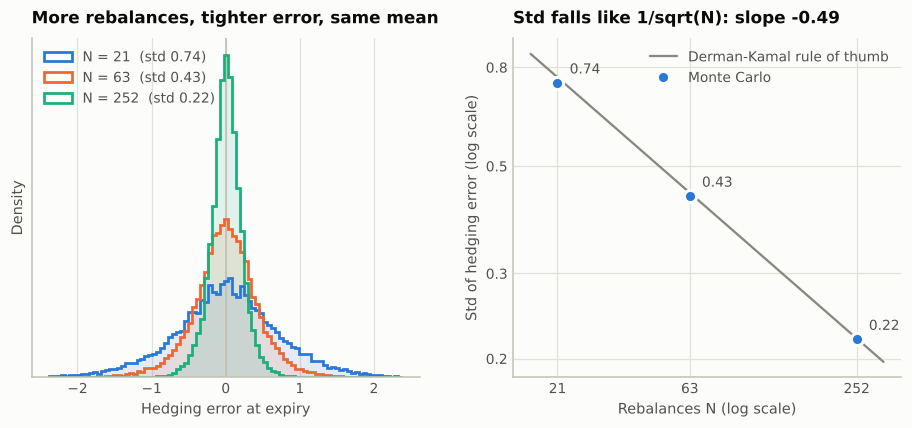

In [11]:
display(freq[["mean", "se", "std", "derman_kamal_std", "std_x_sqrtN", "std_pct_premium", "unhedged_std"]])
print(f"log-log slope of std against N: {freq.attrs['loglog_slope']:.3f}   (theory: -0.5)")
fig = plots.fig_error_by_frequency(freq, pnl)
plt.show()

How to read the table:

* **`mean` against `se`.** Every mean is within two standard errors of zero. Discrete hedging adds noise, not bias. Always quote the standard error; with 20,000 paths it is about 0.003 at $N = 63$, so a mean of 0.002 is indistinguishable from zero.
* **`std` against `derman_kamal_std`.** The PDF predicts 0.76, 0.44 and 0.22. The simulation gives values within a few per cent of those. The rule of thumb is slightly high at small $N$, which matches Kamal and Derman's own table.
* **`std_x_sqrtN`** is roughly constant, and the fitted slope is close to $-0.5$.
* **`std_pct_premium`.** With daily hedging the residual risk is about 10% of the premium.

## 4.2 Each step is skewed, the total is far closer to normal

A single interval's error is a scaled $(1 - Z^2)$: the seller gains a little on roughly two days in three (whenever $|Z| < 1$) and occasionally loses a lot. Boyle and Emanuel (1980) made this point. Adding 63 independent steps brings the total much closer to a normal distribution, by the central limit theorem.

,mean,std,skew,excess_kurtosis,share_gains
error,,,,,
first step,-0.0001,0.0447,-2.8435,12.1442,0.6828
whole life,0.0008,0.4335,-0.1999,1.7115,0.5053


std of the first step: simulated 0.0447, formula sqrt(1/2) * Gamma S^2 sigma^2 dt = 0.0443


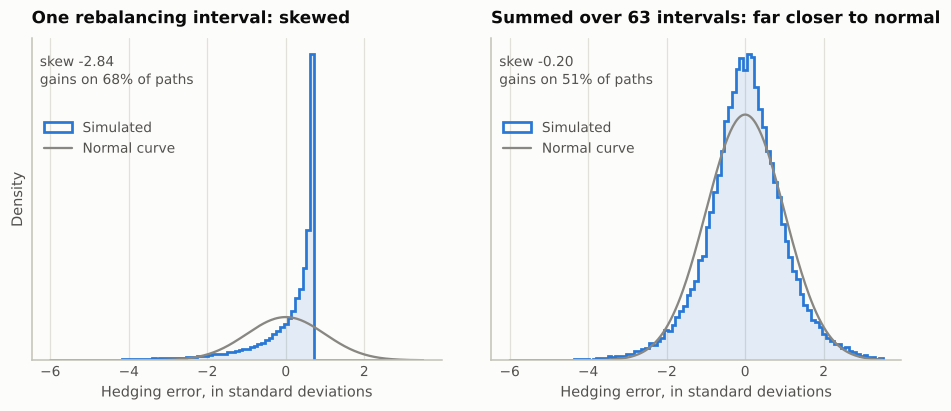

In [12]:
step_table, samples = ex.step_error_study()
display(step_table)
print(f"std of the first step: simulated {step_table.loc['first step', 'std']:.4f}, "
      f"formula sqrt(1/2) * Gamma S^2 sigma^2 dt = {step_table.attrs['first_step_theory_std']:.4f}")
fig = plots.fig_step_vs_total(samples, step_table)
plt.show()

The one-step distribution has a hard ceiling (the most you can earn in a day is that day's theta, when the stock does not move at all) and a long left tail. The simulated one-step standard deviation matches the formula from 4.1.

The total is not perfectly normal: it keeps a small negative skew and fatter tails than the grey curve. Those come from paths that sit near the strike close to expiry, where gamma is very large.

---
# Part 5: What remains is a bet on volatility

Now separate the two volatilities. The option is still **sold and hedged at 20%**, but the stock is simulated with a different **realised** vol. The same random numbers are used for every case, so the only thing that changes is how much the stock moves.

,mean,se,std,vega_rule,exact_value_gap,share_losing
sigma_realised,,,,,,
0.1000,1.9781,0.0038,0.5417,1.9724,1.9833,0.0000
0.1500,0.9904,0.0032,0.4547,0.9862,0.9947,0.0020
0.2000,-0.0011,0.0031,0.4349,0.0000,0.0000,0.4927
0.2500,-0.9939,0.0049,0.6912,-0.9862,-0.9968,0.9757
0.3000,-1.9864,0.0080,1.1256,-1.9724,-1.9941,0.9997


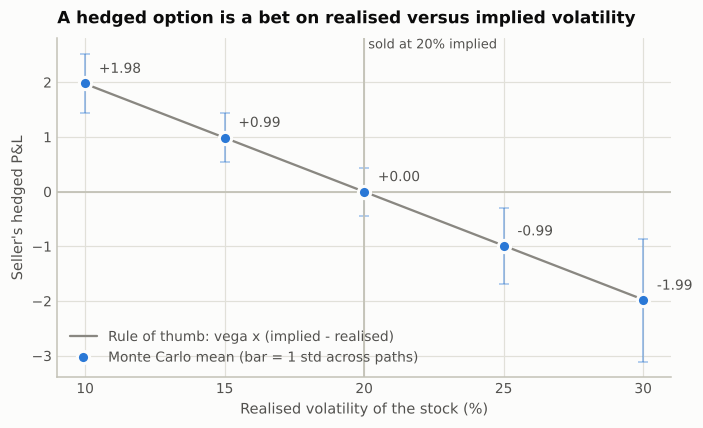

In [13]:
vol_table, detail = ex.vol_bet_study()
display(vol_table)
fig = plots.fig_vol_bet(vol_table)
plt.show()

* The mean P&L lies on the line $\nu \times (\sigma_i - \sigma_r)$. At 25% realised the seller loses about 1.0, as the PDF predicts.
* `exact_value_gap` is $\big(C(\sigma_i) - C(\sigma_r)\big)e^{rT}$, the difference between what the option was sold for and what it was really worth. The simulated mean matches it to within sampling error. The vega rule is its first-order approximation.
* `share_losing`: at 25% realised the hedged seller loses on about 98% of paths. Hedging removed the directional risk and left an almost pure volatility position.

## 5.1 The same vol gap, different outcomes: path dependence

The bars above show that the P&L still varies a lot from path to path. The integral in 2.6 says why: the variance gap is weighted by dollar gamma, so it matters *where* the stock was when it moved. The left panel shows the 25% case. The right panel compares each path's simulated P&L with the discrete version of the formula, $\sum_k \tfrac12\Gamma_k S_k^2\big[\sigma_i^2\delta t - (\delta S_k/S_k)^2\big]$, which uses no cash account at all.

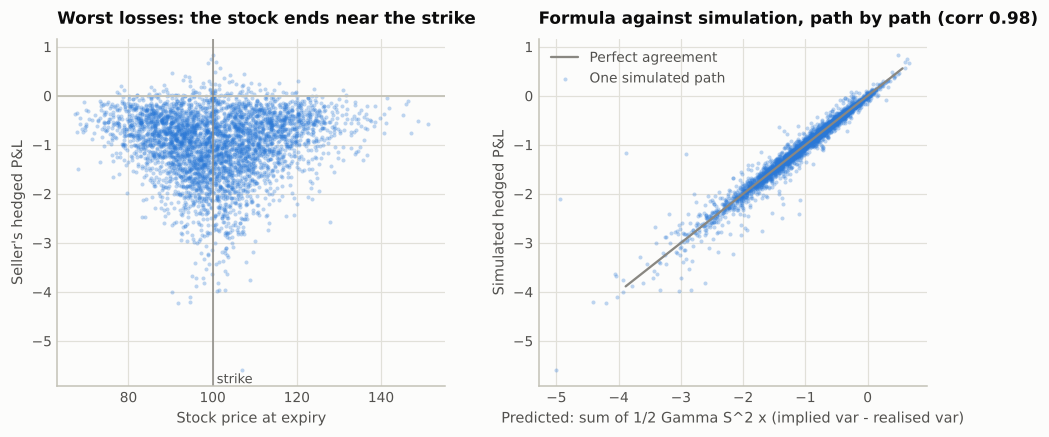

correlation between formula and simulation: 0.982
mean: formula -0.996, simulation -0.994


In [14]:
fig = plots.fig_path_dependence(detail, K)
plt.show()
predicted, simulated = detail["predicted"], detail["pnl"]
print(f"correlation between formula and simulation: {np.corrcoef(predicted, simulated)[0, 1]:.3f}")
print(f"mean: formula {predicted.mean():.3f}, simulation {simulated.mean():.3f}")

The worst losses happen when the stock finishes near the strike: gamma stayed large until the end, so every extra bit of movement was expensive. Paths that ran far away from the strike early lost little, because their gamma died. The formula reproduces the simulation path by path, which is good evidence that the loop and the theory describe the same thing.

## 5.2 The drift does not matter (to the hedger)

$\mu$ dropped out of the PDE in 2.3. Test it: change the stock's expected return from $-10\%$ to $+30\%$ a year and compare the hedged and unhedged seller.

In [15]:
display(ex.drift_study())

,hedged_mean,hedged_std,unhedged_mean,unhedged_std
mu,,,,
-0.1000,-0.0028,0.4338,1.7005,5.1865
0.0400,-0.0011,0.4349,-0.0071,6.5698
0.1500,-0.0004,0.4253,-1.7309,7.6471
0.3000,-0.0111,0.4094,-4.6170,9.0049


The unhedged seller's mean P&L swings from about $+1.7$ to about $-4.6$: selling a naked call is a bet against the stock rising. The hedged seller's mean and standard deviation barely move. Delta hedging is replication, not prediction.

The small changes in the hedged numbers at $\mu = 30\%$ are discrete-hedging effects. A strong trend adds a little to each day's squared move, which nudges the mean down, and it carries the stock away from the strike, where gamma is lower, which trims the standard deviation.

---
# Part 6: Transaction costs make frequency a trade-off

So far, more rebalancing was simply better. Now charge a proportional cost on every trade: `cost = 0.001` means 10 basis points of the value traded, each way.

## 6.1 Leland's adjusted volatility

Over one interval the hedge ratio changes by about $\Gamma\,\delta S$, and $E|\delta S| = \sigma S\sqrt{\delta t}\sqrt{2/\pi}$. With round-trip cost $k$ (one-way $k/2$), the expected cost of that rebalance is

$$\tfrac{k}{2}\,S\,\Gamma\,\sigma S\sqrt{\delta t}\sqrt{2/\pi} \;=\; \tfrac12\Gamma S^2\sigma^2\,\delta t \times \underbrace{\sqrt{\frac{2}{\pi}}\,\frac{k}{\sigma\sqrt{\delta t}}}_{\text{Leland number } Le}$$

It has the same form as the gamma term, scaled by $Le$. So Leland (1985) folds it into the volatility: the option **writer** should price and hedge at

$$\hat\sigma^2 = \sigma^2\,(1 + Le)$$

The extra premium then pays for the expected trading costs. Since $Le \propto 1/\sqrt{\delta t} \propto \sqrt{N}$, costs grow roughly like $\sqrt{N}$ while the hedging error falls like $1/\sqrt{N}$.

For the PDF's example (10 bp one-way, so $k = 0.002$; daily hedging):

In [16]:
show_source(dh.leland_vol)
dt = T / 63
Le = dh.leland_number(sigma, 0.002, dt)
sig_hat = dh.leland_vol(sigma, 0.002, dt)
uplift = dh.bs_price(S0, K, T, r, sig_hat) - dh.bs_price(S0, K, T, r, sigma)
print(f"Leland number {Le:.3f}   adjusted vol {100 * sig_hat:.2f}%   premium rises by {uplift:.3f}"
      f"   (PDF: 0.127, 21.2%, about 0.24)")

def leland_vol(sigma, k_round_trip, dt, short=True):
    """Leland's (1985) cost-adjusted volatility.

        option writer (short):  sigma_hat = sigma * sqrt(1 + Le)
        option buyer  (long):   sigma_hat = sigma * sqrt(1 - Le)   (ill-posed if Le > 1)

    The seller prices AND hedges at the higher sigma_hat, so the extra
    premium covers the expected trading costs.
    """
    le = leland_number(sigma, k_round_trip, dt)
    if short:
        return sigma * np.sqrt(1.0 + le)
    return sigma * np.sqrt(np.maximum(1.0 - le, 0.0))

Leland number 0.127   adjusted vol 21.23%   premium rises by 0.242   (PDF: 0.127, 21.2%, about 0.24)


,mean,std,rmse,mean_cost,one_off_cost,leland_vol,leland_uplift,leland_mean,leland_mean_ex_one_off
N,,,,,,,,,
5,-0.1764,1.4698,1.4803,0.1733,0.1132,0.2035,0.0705,-0.1054,0.0077
10,-0.1990,1.0692,1.0876,0.2062,0.1124,0.2050,0.0993,-0.0983,0.0141
21,-0.2503,0.7665,0.8063,0.2553,0.1133,0.2072,0.1431,-0.1044,0.0089
42,-0.3275,0.5536,0.6432,0.3180,0.1136,0.2101,0.2010,-0.1208,-0.0073
63,-0.3687,0.4617,0.5908,0.3648,0.1134,0.2123,0.2449,-0.1156,-0.0024
126,-0.4676,0.3457,0.5815,0.4675,0.1135,0.2172,0.3423,-0.1127,0.0007
252,-0.6203,0.3024,0.6901,0.6181,0.1132,0.2239,0.4764,-0.1150,-0.0020
504,-0.8246,0.3139,0.8823,0.8243,0.1128,0.2331,0.6595,-0.1129,-0.0003


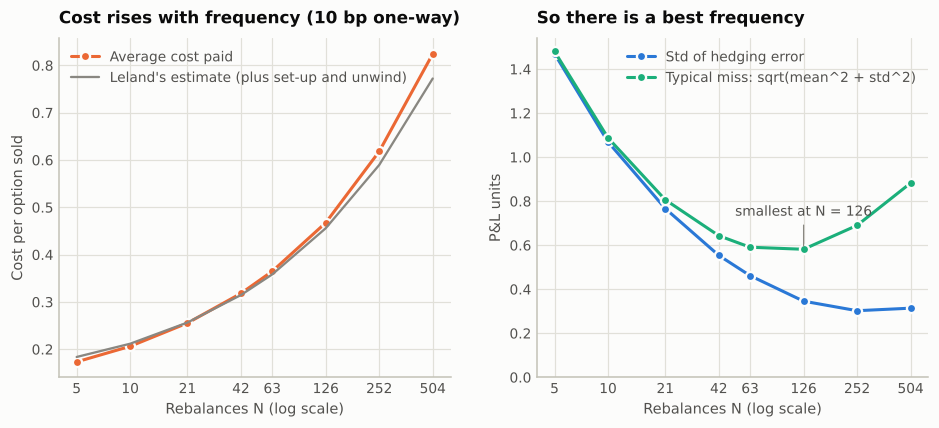

In [17]:
costs = ex.cost_study()
display(costs[["mean", "std", "rmse", "mean_cost", "one_off_cost", "leland_vol", "leland_uplift",
               "leland_mean", "leland_mean_ex_one_off"]])
fig = plots.fig_cost_tradeoff(costs)
plt.show()

* **`mean`** is now negative and gets worse with $N$: it is minus the average cost paid.
* **`std`** falls with $N$ as before, then flattens and even rises slightly at $N = 504$. The costs are themselves random (they depend on the path), so very frequent trading adds cost noise.
* **`rmse`**, $\sqrt{\text{mean}^2 + \text{std}^2}$, is one number for "how far from zero does the seller typically end up". It has a minimum at an interior $N$. Neither "hedge as often as possible" nor "hedge rarely" is best. Where the minimum falls depends on the cost level and on how you weigh a certain cost against an uncertain error, so do not read the particular $N$ as a recommendation.
* **Leland's estimate** tracks the simulated cost closely up to daily hedging and falls a little short for very frequent trading, where $Le$ is no longer small.
* **`leland_mean`** is the mean P&L when the option is priced and hedged at $\hat\sigma$. It is not zero: about $-0.11$ at every $N$. The reason is that Leland's formula covers the cost of *rebalancing* only. Buying the first hedge and selling the last one cost another 0.11 in total (`one_off_cost`). Adding those back, **`leland_mean_ex_one_off`** is within about 0.015 of zero at every $N$. So the adjustment does what it claims, and the set-up and unwind costs need to be charged separately.

One caveat from the literature (PDF 2.8): Kabanov and Safarian (1997) showed that with a fixed cost level, Leland's hedging error does not vanish as $N \to \infty$, contrary to Leland's original claim.

## 6.2 A better rule: no-trade bands

Rebalancing on a clock ignores how far the market moved. Transaction-cost theory (Hodges and Neuberger 1989; Whalley and Wilmott 1997) says the optimal policy is a **no-trade band** around the Black-Scholes delta: do nothing while your delta is inside the band, and trade back to its edge when it leaves.

The experiment below checks the stock 8 times a day and compares three rules on the same paths:

* **time-based**: rehedge every $m$-th check, whatever happened;
* **fixed band**: rehedge only when $|\Delta_{\text{target}} - \Delta_{\text{held}}| > h$;
* **gamma-scaled band**: Whalley and Wilmott's asymptotic band, half-width $\big(\tfrac{3}{2}\,\tfrac{k' S e^{-r\tau}\Gamma^2}{\lambda}\big)^{1/3}$ with $k'$ the one-way cost and $\lambda$ the hedger's risk aversion. It is wider where gamma is large. (The PDF gives only the cube-root scaling; the constant is the form usually quoted from the paper and was not re-derived here.)

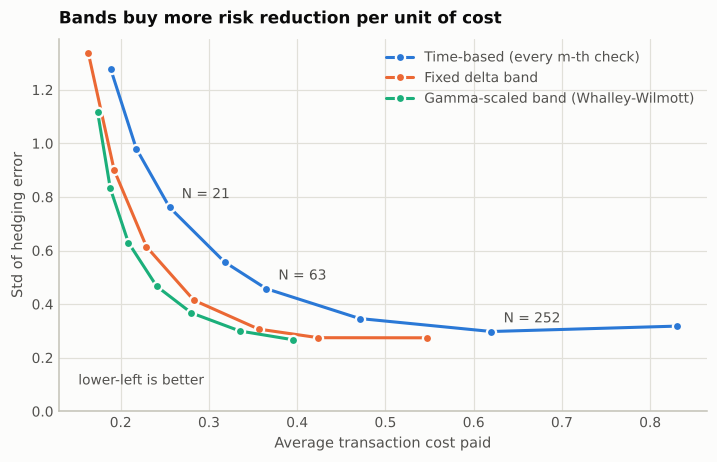

mean_cost    std   trades
rule       setting                                        
time-based N = 504                  0.8308 0.3179 500.6520
           N = 252                  0.6201 0.2977 250.5707
           N = 126                  0.4707 0.3462 125.4626
           N = 63                   0.3649 0.4577  62.8430
           N = 42                   0.3177 0.5572  41.9366
           N = 21                   0.2553 0.7614  20.9931
           N = 12                   0.2176 0.9808  11.9999
           N = 7                    0.1887 1.2772   7.0000
fixed band h = 0.01                 0.5471 0.2742 298.2633
           h = 0.02                 0.4240 0.2746 217.6571
           h = 0.03                 0.3563 0.3068 175.0009
           h = 0.05                 0.2829 0.4144 131.1389
           h = 0.08                 0.2292 0.6140  97.8022
           h = 0.12                 0.1926 0.8997  78.5596
           h = 0.18                 0.1633 1.3376  63.6902
gamma band risk aversion = 30.0     0.3951 0.2671 211.8485
           risk aversion = 10.0     0.3351 0.2996 170.3972
           risk aversion = 3.0      0.2802 0.3670 133.0179
           risk aversion = 1.0      0.2408 0.4665 106.3625
           risk aversion = 0.3      0.2087 0.6298  84.1993
           risk aversion = 0.1      0.1881 0.8326  69.1809
           risk aversion = 0.03     0.1739 1.1169  56.9720

In [18]:
frontier = ex.band_frontier()
fig = plots.fig_frontier(frontier)
plt.show()
display(frontier[frontier["rule"] != "fixed band, trade to target"]
        .set_index(["rule", "setting"])[["mean_cost", "std", "trades"]])

Both band rules sit below and to the left of the time-based curve: for the same cost they leave less hedging error, and for the same error they cost less. Compare daily time-based hedging ($N = 63$: cost about 0.36, error std about 0.46) with a fixed band at a similar cost (std about 0.31) or the gamma-scaled band (std about 0.30 at slightly lower cost).

The gamma-scaled band does a little better than the fixed band across the range. Both band rules trade far more often than the daily clock (around 170 trades against 63) and still pay less: trading only back to the edge of the band keeps each trade small, and nothing is spent on moves that soon reverse.

---
# Part 7: Which volatility should you hedge with?

Suppose you sell at 20% implied and you *know* the stock will realise 30%. (You would not sell in that case; the point is to see the mechanics. Flip the signs for the buyer.) You can compute your hedge delta with either volatility. Ahmad and Wilmott (2005) show the choice matters:

* **Hedge at realised vol.** The hedge replicates the option's true value, so the total P&L is locked in at $\big(C(\sigma_i) - C(\sigma_r)\big)e^{rT}$. But the option is *marked* at implied vol, so your delta is "wrong" relative to the mark, and the daily mark-to-market P&L swings with the stock.
* **Hedge at implied vol.** The delta matches the mark, so the daily P&L is smooth: a steady gamma-versus-theta bleed. But the total depends on the path, as in Part 5.

With daily hedging the discretisation noise from Part 4 blurs the difference, so the experiment also uses 32 rebalances a day ($N = 2016$) to get close to the continuous-time result.

mean    std     p05     p95  daily_pnl_std
N    hedge_vol                                              
63   implied   -2.0162 1.1323 -4.1111 -0.5655         0.1073
     realised  -2.0018 0.6563 -3.0676 -0.9706         0.1498
2016 implied   -1.9943 0.9141 -3.5656 -0.6561         0.0195
     realised  -1.9957 0.1184 -2.1861 -1.8056         0.1147

locked-in value (C(20%) - C(30%)) e^(rT) = -1.994


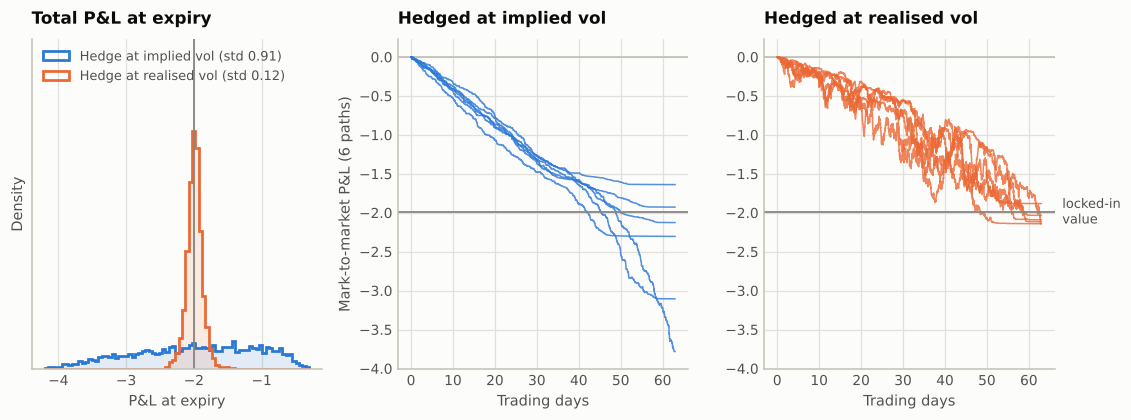

In [19]:
hv, hv_paths = ex.hedge_vol_study()
display(hv)
print(f"locked-in value (C(20%) - C(30%)) e^(rT) = {hv.attrs['locked_in']:.3f}")
fig = plots.fig_hedge_vol(hv, hv_paths)
plt.show()

At $N = 2016$:

* Both choices have the **same mean**, the locked-in value.
* Hedging at **realised** vol gives a terminal standard deviation of about 0.12 against about 0.91 at implied: the total is nearly certain. But `daily_pnl_std`, the bumpiness of the ride, is about six times larger.
* Hedging at **implied** vol gives the smooth lines in the middle panel, which then fan out to very different totals.

At $N = 63$ the realised-vol hedge still has a standard deviation of about 0.66. That is the discrete-hedging noise from Part 4, which no choice of hedging vol removes.

In practice many desks hedge at implied because the hedge then matches how the book is marked, and because the true future volatility is not known anyway.

---
# Part 8: P&L attribution. Where did the money go?

Desks decompose each day's P&L into its Greek components. For the short, hedged book $\Pi = \text{cash} + \Delta S - V$, a Taylor expansion of $V$ over one step gives

$$\delta\Pi \approx \underbrace{-\Theta\,\delta t}_{\text{theta income}} \;\underbrace{-\,\tfrac12\Gamma\,\delta S^2}_{\text{gamma loss}} \;+\; \underbrace{r\cdot\text{cash}\cdot\delta t}_{\text{financing}} \;\underbrace{-\,\nu\,\delta\sigma_{\text{mark}}}_{\text{vega}} \;-\; \text{costs} \;+\; \text{residual}$$

The residual collects the higher-order terms. If it is small, the decomposition explains the P&L. Here is one path simulated with 25% volatility against 20% implied (the cell prints what this particular path actually realised).

realised vol on this path: 22.9%


,t,S,theta,gamma,financing,dividend,vega,delta_mismatch,cost,residual,total
step,,,,,,,,,,,
0,0.0040,99.9927,0.0395,-0.0000,-0.0082,0.0000,-0.0000,-0.0000,-0.0000,0.0001,0.0314
1,0.0079,101.6573,0.0397,-0.0551,-0.0082,0.0000,-0.0000,0.0000,-0.0000,0.0014,-0.0222
2,0.0119,102.8551,0.0403,-0.0272,-0.0092,0.0000,-0.0000,0.0000,-0.0000,0.0003,0.0042
3,0.0159,104.0381,0.0403,-0.0253,-0.0099,0.0000,-0.0000,0.0000,-0.0000,-0.0000,0.0050
4,0.0198,106.7282,0.0398,-0.1230,-0.0106,0.0000,-0.0000,0.0000,-0.0000,0.0047,-0.0891


,theta,gamma,financing,dividend,vega,delta_mismatch,cost,residual,total
sum over the option's life,3.0888,-3.0531,-0.6437,0.0000,0.0000,0.0000,0.0000,-0.0010,-0.6090


theta + financing = +2.445   gamma = -3.053   total = -0.609   largest one-step residual = 0.0256


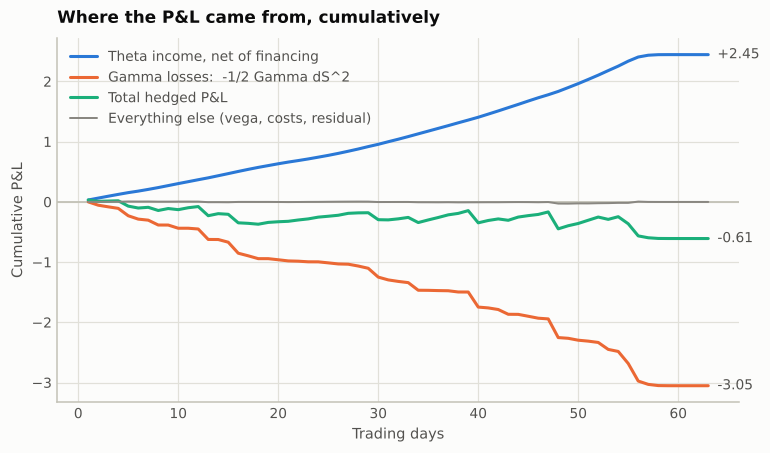

In [20]:
S_hot = dh.simulate_gbm(S0, r, 0.25, T, 63, 1, np.random.default_rng(12))[0]
att = dh.attribute_pnl(S_hot, K, T, r, sigma)
print(f"realised vol on this path: {100 * dh.realised_vol(S_hot, T)[0]:.1f}%")
display(att.head(5))
totals = att.drop(columns=["t", "S"]).sum()
display(totals.to_frame("sum over the option's life").T)
print(f"theta + financing = {totals.theta + totals.financing:+.3f}   gamma = {totals.gamma:+.3f}   "
      f"total = {totals.total:+.3f}   largest one-step residual = {att.residual.abs().max():.4f}")
fig = plots.fig_attribution(att)
plt.show()

* **Theta net of financing** rises steadily: the seller collects about 2.45 over the life.
* **Gamma losses** fall in jumps, one for each large move, to about $-3.05$.
* Their sum is the hedged P&L, about $-0.61$. The residual is negligible, so second-order Greeks explain essentially everything on this path.

The premium was 4.49 but the "carry" collected is only 2.45, because this path wandered away from the strike and its gamma and theta both faded. Had it stayed near 100, both lines would have been steeper.

`vega` is zero here because the option is marked at a constant 20%. It appears in the real-data section, where implied vol moves every day.

---
# Part 9: The same exercise on real data

Everything above happened in a world where Black-Scholes is true by construction. This section replays the hedge on S&P 500 history (PDF 4.2). The data comes from FRED, the St. Louis Fed's database:

| Series | What it is | Used as |
|---|---|---|
| `SP500` | S&P 500 index, daily close | the underlying |
| `DGS3MO` | 3-month Treasury yield, bond-equivalent basis | $r$, after converting to continuous compounding |
| `VXVCLS` | Cboe S&P 500 3-Month Volatility Index | the implied vol the option is sold at |
| `VIXCLS` | Cboe VIX (30-day) | reference only |

**The experiment.** On each start date, sell a 3-month at-the-money call on the index at that day's 3-month implied vol, hedge it once a day at that same vol with no costs, and settle 63 trading days later. Repeat for every start date. P&L is quoted in per cent of the starting index level.

**Read this before the results.**

* The VIX family measures variance-swap-style volatility across many strikes. It is not the Black-Scholes implied vol of one ATM option, and it normally sits above ATM implied vol. So the premium here is somewhat too high.
* Hedging happens at daily closes; overnight gaps count as realised vol and cannot be hedged.
* The dividend yield is an assumed constant $q = 1.3\%$, not data.
* The windows overlap almost completely, so about 2,450 windows are nowhere near 2,450 independent observations. Ten years is one history.
* No costs, no bid-ask spread on the option, no margin. **This is an illustration of the mechanics, not a backtest of a strategy.**

In [21]:
from delta_hedging import realdata as rd

data = rd.load_market_data(cache_dir=ROOT / "data" / "raw")
print(f"{len(data)} trading days, {data.index[0]:%Y-%m-%d} to {data.index[-1]:%Y-%m-%d}")
display(data.tail(3))

y = 4.32
print(f"yield conversion example: {y}% bond-equivalent -> "
      f"{100 * rd.bond_equivalent_to_continuous(y):.4f}% continuous  (ln(1 + y * 91/365) / (91/365))")

2514 trading days, 2016-11-14 to 2026-11-13


,spx,r,iv_3m,iv_1m
date,,,,
2026-11-11,"7,619.3800",0.0428,0.1924,0.1749
2026-11-12,"7,592.4000",0.0430,0.2006,0.1870
2026-11-13,"7,561.6700",0.0430,0.2006,0.1870


yield conversion example: 4.32% bond-equivalent -> 4.2969% continuous  (ln(1 + y * 91/365) / (91/365))


,mean,std,min,50%,max
implied,0.2068,0.0648,0.1185,0.1952,0.7298
realised,0.1583,0.0921,0.0526,0.1339,0.6218
premium_pct,4.2589,1.2434,2.3325,4.1066,14.2940
pnl_pct,1.0098,1.0449,-5.0494,1.1325,4.8257
vega_pred_pct,0.9579,1.8220,-9.2068,1.2861,6.3856
gamma_pred_pct,1.0219,1.0518,-5.0713,1.1508,4.8894
unhedged_pct,-0.6335,4.1781,-28.2685,-0.3835,6.9971


windows: 2451   implied above realised in 84% of them   hedged seller's P&L positive in 86%
correlation of hedged P&L with the gamma-weighted formula: 0.993;  with vega x vol gap: 0.808


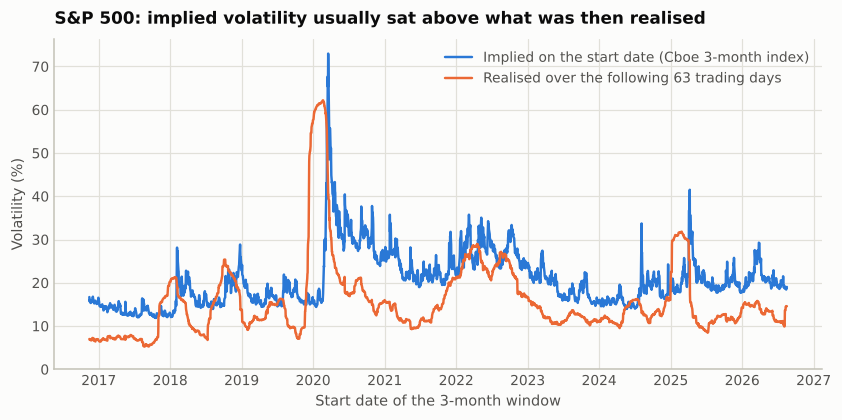

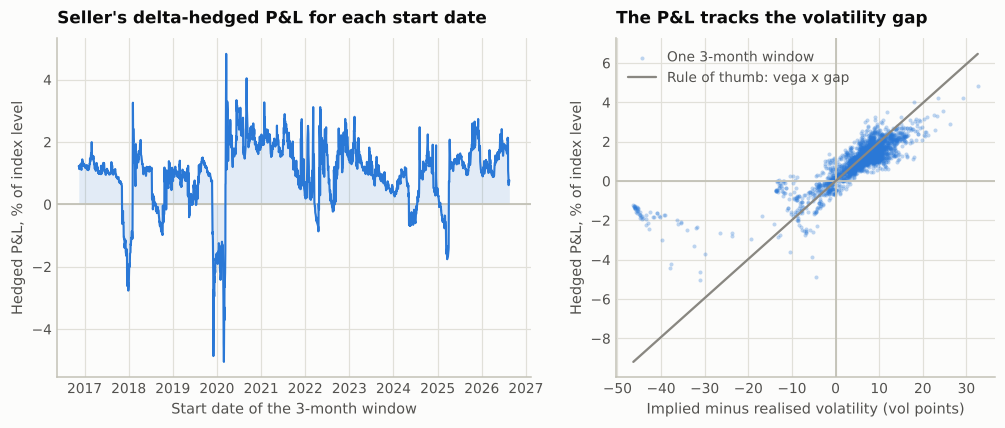

In [22]:
roll = rd.rolling_replay(data, n_days=63, q=0.013)
gap = roll["implied"] - roll["realised"]
display(roll[["implied", "realised", "premium_pct", "pnl_pct", "vega_pred_pct", "gamma_pred_pct",
              "unhedged_pct"]].describe().T[["mean", "std", "min", "50%", "max"]])
print(f"windows: {len(roll)}   implied above realised in {100 * (gap > 0).mean():.0f}% of them"
      f"   hedged seller's P&L positive in {100 * (roll.pnl_pct > 0).mean():.0f}%")
print(f"correlation of hedged P&L with the gamma-weighted formula: "
      f"{roll.pnl_pct.corr(roll.gamma_pred_pct):.3f};  with vega x vol gap: "
      f"{roll.pnl_pct.corr(roll.vega_pred_pct):.3f}")
fig = plots.fig_rolling_vols(roll)
plt.show()
fig = plots.fig_rolling_pnl(roll)
plt.show()

What the history shows, within the caveats above:

* **The mechanics carry over.** The gamma-weighted formula from 2.6 explains the hedged P&L of real windows almost as well as simulated ones. The P&L of a delta-hedged option on real data is still realised against implied variance, weighted by dollar gamma.
* **Implied was usually above subsequent realised** in this sample, so the hedged seller usually made a small gain, about 1% of the index level on average. This is consistent in sign with Bakshi and Kapadia (2003), who found that delta-hedged long S&P 500 option positions lose on average, and with a negative volatility risk premium. The size here is overstated by the VIX-for-ATM substitution and by ignoring costs.
* **The losses are concentrated.** Windows that ran into February 2018, March 2020 and April 2025 lost up to about 2.8%, 5.0% and 1.8% of the index level, against a typical gain of about 1%. The seller is paid for bearing exactly that risk.
* **The vega rule breaks in a crash.** In the right-hand chart the points at the far left lie well above the grey line: windows with a vol gap beyond $-35$ points lost about 1.8% on average, where the vega rule says about 8.6%. The index had fallen so far below the strike that the call's gamma vanished, so most of the extra variance was no longer charged to it. That is the path dependence of 5.1 on real data, and it is why the gamma-weighted formula fits so much better than the vega rule.

## 9.1 Two windows in detail: a calm one and a crash

In the charts the option is re-marked each day at that day's implied vol, so the daily P&L includes **vega P&L** as it would on a desk. The hedge delta still uses the vol of the start date. The table then attributes each window's P&L twice: once with the option marked at the sale vol throughout, once re-marked daily.

calm: sold 01 Jun 2017   implied 12.4%   realised 7.4%   premium 2.43%   final P&L +1.27%   worst mark-to-market -0.08% on 06 Jun 2017   largest daily move 1.6%


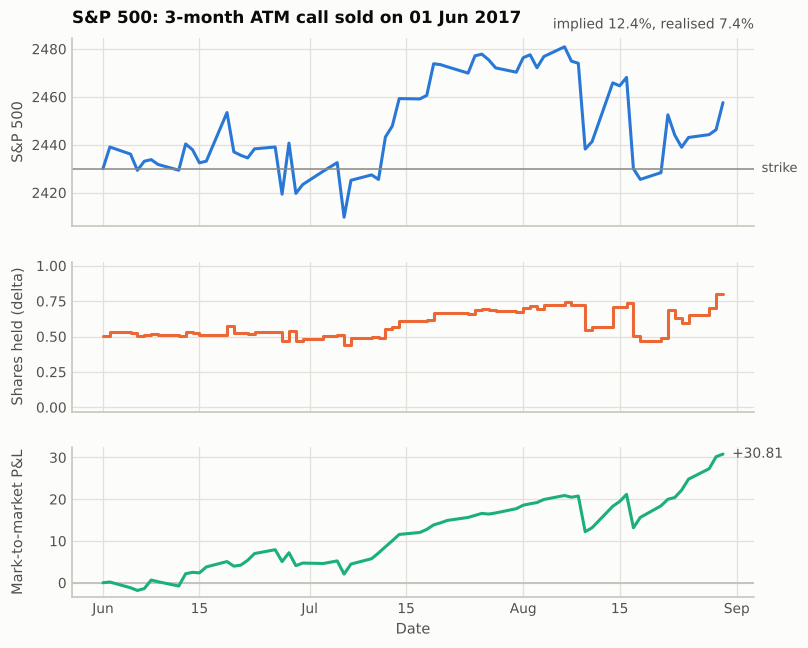

crash: sold 03 Feb 2020   implied 18.0%   realised 61.5%   premium 3.62%   final P&L -2.21%   worst mark-to-market -3.75% on 17 Mar 2020   largest daily move 12.8%


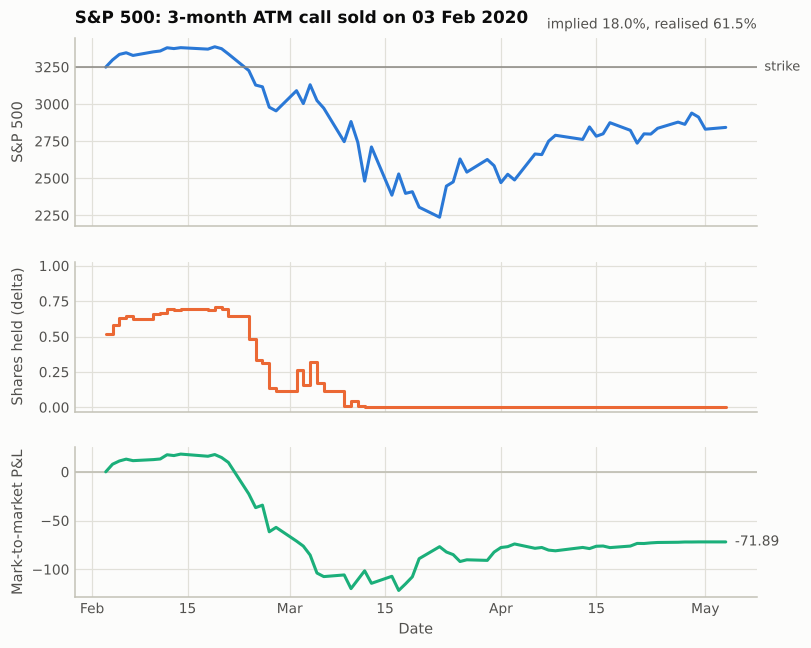

P&L attribution, in % of the starting index level:


theta + carry   gamma    vega  delta mismatch  residual   total
calm  marked at the sale vol         2.0949 -0.7694  0.0000          0.0000   -0.0575  1.2680
      re-marked daily                2.2955 -0.7081 -0.1415         -0.0391   -0.1389  1.2680
crash marked at the sale vol         0.6391 -3.1937  0.0000          0.0000    0.3420 -2.2126
      re-marked daily                2.0776 -5.6514 -5.4066          3.7756    2.9923 -2.2126

In [23]:
rows = {}
for tag, start in (("calm", "2017-06-01"), ("crash", "2020-02-03")):
    led, s = rd.replay_window(data, start)
    pct = 100 / s["S0"]
    print(f"{tag}: sold {s['start']:%d %b %Y}   implied {100 * s['implied']:.1f}%   "
          f"realised {100 * s['realised']:.1f}%   premium {s['premium'] * pct:.2f}%   "
          f"final P&L {s['pnl'] * pct:+.2f}%   worst mark-to-market {led['pnl'].min() * pct:+.2f}% "
          f"on {led['pnl'].idxmin():%d %b %Y}   largest daily move "
          f"{100 * np.abs(np.diff(np.log(led['S']))).max():.1f}%")
    for label, marks in (("marked at the sale vol", s["implied"]),
                         ("re-marked daily", led["implied"].to_numpy()[None, :])):
        a = dh.attribute_pnl(led["S"].to_numpy(), s["K"], s["T"], s["r"], s["implied"],
                             sigma_mark=marks, q=s["q"]).drop(columns=["t", "S"]).sum() * pct
        rows[(tag, label)] = {
            "theta + carry": a.theta + a.financing + a.dividend, "gamma": a.gamma, "vega": a.vega,
            "delta mismatch": a.delta_mismatch, "residual": a.residual, "total": a.total}
    fig = plots.fig_single_path(
        led, s["K"], x=led.index, xlabel="Date", value_col="pnl", value_label="Mark-to-market P&L",
        price_label="S&P 500", title=f"S&P 500: 3-month ATM call sold on {s['start']:%d %b %Y}",
        note=f"implied {100 * s['implied']:.1f}%, realised {100 * s['realised']:.1f}%")
    plt.show()
print("P&L attribution, in % of the starting index level:")
display(pd.DataFrame(rows).T)

* **Calm window (June 2017).** Realised vol was well below implied. Theta income exceeded gamma losses nearly every day and the P&L climbed steadily. The two attributions differ little, because implied vol hardly moved.
* **Crash window (February 2020).** Sold at 18% implied; the index then realised over 60%, with daily moves of up to almost 13%. Marked at the sale vol, the story is simple: gamma losses of about 3.2% against theta of about 0.65%. The hedge ratio fell to zero as the call went far out of the money, after which the book had almost no exposure left, so the loss stopped growing even though the index kept falling.
* **Re-marking changes the timing, not the total.** Both attributions of a window add up to the same final P&L. But on 17 March 2020 the mark-to-market loss was about 3.7%, well beyond the final 2.2%: implied vol had jumped from 18% to over 70%, so the short option was marked far higher before decaying back to its payoff. A desk with loss limits lives with the worst point, not the final figure.
* **Where the decomposition breaks.** In the re-marked crash attribution the vega loss (about $-5.4\%$) is offset by a large delta-mismatch term (the hedge delta was computed at 18% while the option was marked at much higher vols) and by a residual of about $+3\%$. A residual that size says a second-order expansion in spot and a first-order one in vol no longer describe what happened. Cross effects between spot and vol sit in that residual, along with the gap risk listed in 1.3. In the calm window the residual is small either way.

---
# Part 10: Common bugs, and what they look like

Each of these produces plausible-looking numbers. The Monte Carlo checks from Part 4 are how you catch them (PDF 3.7). Three are demonstrated below.

In [24]:
def hedge_with_bug(S, bug=None):
    "The 20-line loop again, with a switch that introduces one mistake."
    n = S.shape[1] - 1
    dt, look = T / n, (1 if bug == "look-ahead" else 0)
    growth = 1.0 if bug == "no interest" else np.exp(r * dt)
    delta = dh.bs_delta(S[:, look], K, T - look * dt, r, sigma)   # look-ahead peeks at S[:, 1]
    cash = dh.bs_price(S0, K, T, r, sigma) - delta * S[:, 0]
    for i in range(1, n):
        cash = cash * growth
        j = i + look                                              # ... and at S[:, i + 1] here
        tau = T - j * dt
        new = dh.bs_delta(S[:, j], K, tau, r, sigma) if tau > 0 else (S[:, j] > K) * 1.0
        cash -= (new - delta) * S[:, i]
        delta = new
    return cash * growth + delta * S[:, -1] - np.maximum(S[:, -1] - K, 0.0)


S = dh.simulate_gbm(S0, r, sigma, T, 63, 20_000, np.random.default_rng(42))
rows = {name: dh.summarize(hedge_with_bug(S, bug)) for name, bug in
        (("correct", None), ("look-ahead in the hedge", "look-ahead"),
         ("forgot interest on cash", "no interest"))}
display(pd.DataFrame(rows).T[["mean", "se", "std"]])

# Drift error: using mu instead of mu - sigma^2/2 in the log step.
Z = np.random.default_rng(0).standard_normal(400_000)
right = S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
wrong = S0 * np.exp(r * T + sigma * np.sqrt(T) * Z)
print(f"E[S_T] should be {S0 * np.exp(r * T):.3f}:  correct step {right.mean():.3f},  "
      f"without the -sigma^2/2 term {wrong.mean():.3f}")

,mean,se,std
correct,0.0023,0.0031,0.4352
look-ahead in the hedge,4.0017,0.0109,1.5387
forgot interest on cash,0.5204,0.0035,0.4913


E[S_T] should be 101.005:  correct step 101.008,  without the -sigma^2/2 term 101.514


| Bug | Symptom | Why |
|---|---|---|
| **Look-ahead**: delta for the next interval computed from the *next* price | Mean P&L strongly positive | The hedge knows where the stock is going. No real strategy can. |
| **Forgetting interest on cash** | Mean biased by about $r \times$ average cash $\times\, T$, here about $+0.5$ | The desk borrows about 50 to buy shares and is not charged for it. |
| **Drift error**: $\mu$ instead of $\mu - \tfrac12\sigma^2$ in the log step | $E[S_T]$ too high | The paths have the wrong distribution. |
| Wrong time to expiry at the last step | NaN deltas, or every delta shifted | $\tau = 0$ divides by zero. Rebalance only while $\tau > 0$. |
| Mixing implied and realised vol | The volatility bet disappears or has the wrong sign | Paths use $\sigma_r$; pricing and hedging use $\sigma_i$. |
| Wrong cost convention | Costs off by a factor of two | Charge the absolute number of shares traded times the price; Leland's $k$ is round-trip. |
| Comparing present and terminal values | A small unexplained bias | The premium is a time-0 amount, the P&L a time-$T$ amount. |
| Monte Carlo noise read as signal | "Finding" an edge that is not there | Always report the standard error. |

---
# Part 11: Check your understanding

Ten interview-style questions from the PDF, with short answers and where this notebook shows the evidence.

1. **Why doesn't the expected return $\mu$ appear in the Black-Scholes price?** The delta hedge cancels the $dW$ term and $\mu$ cancels with it; a riskless portfolio must earn $r$. *Sections 2.3 and 5.2.*
2. **You are short an ATM option, delta-hedged. The stock jumps 5% either way. Do you make or lose money?** You lose about $\tfrac12\Gamma S^2 (0.05)^2$, whichever direction: you are short gamma. With the default Greeks that is about $0.5 \times 0.0394 \times 100^2 \times 0.0025 \approx 0.49$. *Sections 1.4 and 3.1.*
3. **What does a delta-hedged option position bet on?** Realised against implied variance, weighted by dollar gamma along the path. *Part 5.*
4. **If you hedge four times as often, what happens to your hedging error?** Its standard deviation roughly halves; the mean stays near zero; costs roughly double. *Sections 4.1 and 6.1.*
5. **Where is gamma highest, and why does it matter?** At the money, close to expiry. Hedging error and cost concentrate there. *Sections 5.1 and 9.1.*
6. **Why hedge an index option with futures?** Liquidity, cost, one trade instead of 500, no stock borrow. The hedge size is scaled by $e^{-(r-q)T^*}$ for the futures maturity. *Not simulated here.*
7. **What does Leland's adjusted volatility do?** For the seller it raises the vol used to price and hedge, by a factor that grows with cost and rebalancing frequency, so the premium covers expected rebalancing costs. *Section 6.1.*
8. **Should you hedge with implied or realised volatility?** Implied gives a smooth daily P&L but a path-dependent total. Realised, if you knew it, locks in the total but makes the mark-to-market noisy. *Part 7.*
9. **Why is the total discrete-hedging error close to normal when each step is skewed?** Each step is a scaled $(1 - Z^2)$; many independent steps sum to something near normal. *Section 4.2.*
10. **Empirically, do delta-hedged index option buyers make money?** On average no (Bakshi and Kapadia 2003). The ten years replayed here agree in sign, with heavy caveats. *Part 9.*

# Sources

The full bibliography, with links and what each source was used for, is in [`docs/SOURCES.md`](../docs/SOURCES.md). The data manifest (series, download URLs, dates, checksums) is in [`data/manifest.json`](../data/manifest.json).

The main ones: Black and Scholes (1973) and Merton (1973) for the hedging argument and the formula; Kamal and Derman (Goldman Sachs, 1998) for the discrete-hedging rule of thumb; Boyle and Emanuel (1980) for the skewed per-step error; El Karoui, Jeanblanc-Picqué and Shreve (1998) for the gamma-weighted P&L formula; Leland (1985), Kabanov and Safarian (1997), Hodges and Neuberger (1989) and Whalley and Wilmott (1997) for transaction costs; Ahmad and Wilmott (2005) and Carr's FAQ for the choice of hedging volatility; Bakshi and Kapadia (2003) for the empirical evidence; Glasserman (2003) for exact simulation; Hull, Taleb and Sinclair for textbook and practitioner treatment.